# Ajman Business Hackathon 2026 — Forecasting Kit
**Practice run on real Ajman DED open data (new economic licences, Jan 2010 – Jun 2026).**

How to use on the day:
1. Run `python prepare_data.py` (or replace `data/ajman_monthly.csv` with the organisers' data, keeping a `month` column + your target column).
2. Change the **CONFIG** cell (target column, training start, forecast horizon).
3. *Run All*. Charts for the slides are saved to `outputs/`, the dashboard to `outputs/dashboard.html`.

Pipeline: **load → explore → seasonal-naive baseline → SARIMAX / Prophet / XGBoost → back-test → shock estimate → scenarios → stock-flow equation → export.**

In [1]:
# CONFIG — the only cell you should need to change on the day
TARGET        = "total"        # column to forecast: total / professional / commercial / industrial / permits
TRAIN_START   = "2018-01"      # earliest month used for training (2018 back-tested best; 2016 also works)
NORMAL_TEST   = ("2024-10", "2026-02")   # train up to first date, test until second ("normal times")
SHOCK_TEST    = ("2026-02", "2026-06")   # train up to Feb 2026, test the shock months
HORIZON_END   = "2027-12"      # forecast up to this month
USE_PROPHET   = True           # set False if prophet won't install on a laptop

# Stock-flow inputs (from DED's Q1 2026 press release — replace with the organisers' figures)
ACTIVE_NOW        = 41_603     # active licences, end of Q1 2026
ACTIVE_GROWTH_YOY = 0.16       # +16% year on year
RENEWALS_PER_MONTH  = 8_777 / 3
CANCELLED_PER_MONTH = 199 / 3

In [2]:
import warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import forecast_kit as fk
warnings.filterwarnings("ignore")
import logging; logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
NAVY, PURPLE, TEAL, GREY, RED = "#2B1B5C", "#5B3FB5", "#1A9E8F", "#9A9A9A", "#C8423B"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

df = fk.load_monthly("data/ajman_monthly.csv")
print(f"{len(df)} months: {df.index[0]} to {df.index[-1]}; missing {TARGET}: {df[TARGET].isna().sum()}")
df.loc["2025-01":, ["professional","commercial","industrial","other","total","permits","ramadan_share","disruption"]]

198 months: 2010-01 to 2026-06; missing total: 9


,professional,commercial,industrial,other,total,permits,ramadan_share,disruption
month,,,,,,,,
2025-01,360.0,295.0,28.0,3.0,686.0,89.0,0.000000,0
2025-02,366.0,264.0,23.0,7.0,660.0,78.0,0.000000,0
2025-03,335.0,208.0,7.0,2.0,552.0,100.0,0.935484,0
2025-04,354.0,230.0,12.0,1.0,597.0,92.0,0.000000,0
2025-05,385.0,289.0,20.0,3.0,697.0,106.0,0.000000,0
2025-06,287.0,234.0,13.0,3.0,537.0,91.0,0.000000,0
2025-07,409.0,270.0,14.0,4.0,697.0,100.0,0.000000,0
2025-08,345.0,243.0,13.0,1.0,602.0,94.0,0.000000,0
2025-09,419.0,253.0,27.0,2.0,701.0,95.0,0.000000,0


## 1. Explore
Gaps are **months DED did not publish** (Jul–Dec 2022, Nov–Dec 2024) and a partial month (Oct 2024). They stay as NaN — SARIMAX and Prophet handle missing months natively.

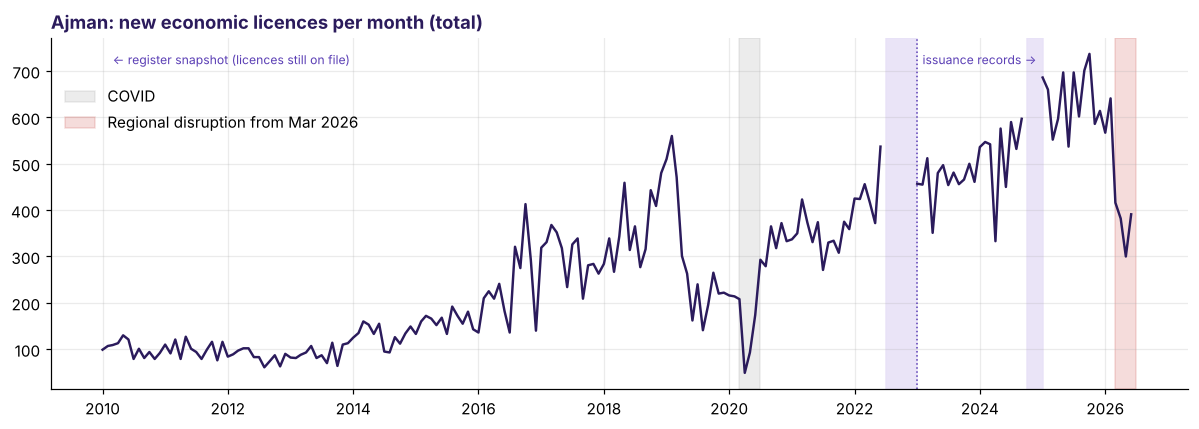

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
y = df[TARGET]
ax.plot(y.index.to_timestamp(), y.values, color=NAVY, lw=1.6)
for a, b, lab, c in [("2020-03", "2020-06", "COVID", GREY), ("2026-03", "2026-06", "Regional disruption from Mar 2026", RED)]:
    ax.axvspan(pd.Period(a, "M").to_timestamp(), pd.Period(b, "M").end_time, color=c, alpha=0.18, label=lab)
for a, b in [("2022-07", "2022-12"), ("2024-10", "2024-12")]:
    ax.axvspan(pd.Period(a, "M").to_timestamp(), pd.Period(b, "M").end_time, color="#E8E2F7", alpha=0.9)
ax.axvline(pd.Timestamp("2023-01-01"), color=PURPLE, ls=":", lw=1)
ax.text(pd.Timestamp("2023-02-01"), y.max()*0.97, "issuance records →", color=PURPLE, fontsize=8)
ax.text(pd.Timestamp("2010-03-01"), y.max()*0.97, "← register snapshot (licences still on file)", color=PURPLE, fontsize=8)
ax.set_title(f"Ajman: new economic licences per month ({TARGET})", loc="left", fontweight="bold", color=NAVY)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9), frameon=False)
plt.tight_layout(); plt.savefig(OUT / "fig1_history.png", dpi=200); plt.show()

In [4]:
# Year-on-year view of the shock: Mar–Jun 2026 vs Mar–Jun 2025
yoy = pd.DataFrame({
    "2025": df.loc["2025-01":"2025-06", ["total", "permits"]].values.T.tolist()[0],
    "2026": df.loc["2026-01":"2026-06", ["total", "permits"]].values.T.tolist()[0]},
    index=["Jan", "Feb", "Mar", "Apr", "May", "Jun"])
yoy["change_%"] = (yoy["2026"] / yoy["2025"] - 1) * 100
mj25, mj26 = df.loc["2025-03":"2025-06", "total"].sum(), df.loc["2026-03":"2026-06", "total"].sum()
pm25, pm26 = df.loc["2025-03":"2025-06", "permits"].sum(), df.loc["2026-03":"2026-06", "permits"].sum()
print(f"New licences Mar–Jun: 2025 = {mj25:.0f}, 2026 = {mj26:.0f}  ({mj26/mj25-1:+.1%})")
print(f"Economic permits Mar–Jun: 2025 = {pm25:.0f}, 2026 = {pm26:.0f}  ({pm26/pm25-1:+.1%})  ← existing businesses held up better")
yoy.round(1)

New licences Mar–Jun: 2025 = 2383, 2026 = 1489  (-37.5%)
Economic permits Mar–Jun: 2025 = 389, 2026 = 332  (-14.7%)  ← existing businesses held up better


,2025,2026,change_%
Jan,686.0,567.0,-17.3
Feb,660.0,641.0,-2.9
Mar,552.0,416.0,-24.6
Apr,597.0,382.0,-36.0
May,697.0,300.0,-57.0
Jun,537.0,391.0,-27.2


,2025-03..2025-06,2026-03..2026-06,change_%
professional,1361.0,758.0,-44.3
commercial,961.0,677.0,-29.6
industrial,52.0,44.0,-15.4


,2025-03..2025-06,2026-03..2026-06,change_%
Buildings Cleaning Services,205,37,-82.0
Delivery Services Coordination & Provision,27,7,-74.1
All Kind Building Projects Contracting,76,29,-61.8
Administrative Services - Businessmen Services,28,14,-50.0
Restaurant,72,41,-43.1
Décor Works,33,19,-42.4
Real Estate Purchase and Sale Brokerage,38,23,-39.5
Buildings Maintenance,202,125,-38.1
Building & Construction Materials Trading,34,22,-35.3
Women Personal Care and Beauty,47,31,-34.0


,2025-03..2025-06,2026-03..2026-06,change_%
Ajman Industrial 2,176,69,-60.8
Masfout 8,196,77,-60.7
Rashideya 1,75,32,-57.3
Rashideya 3,65,29,-55.4
Rawdha 3,67,31,-53.7
Ajman Industrial 1,112,52,-53.6
Jurf Industrial 2,98,48,-51.0
Masfout 3,89,49,-44.9
Jurf Industrial 1,93,60,-35.5
Nakheel 2,74,50,-32.4


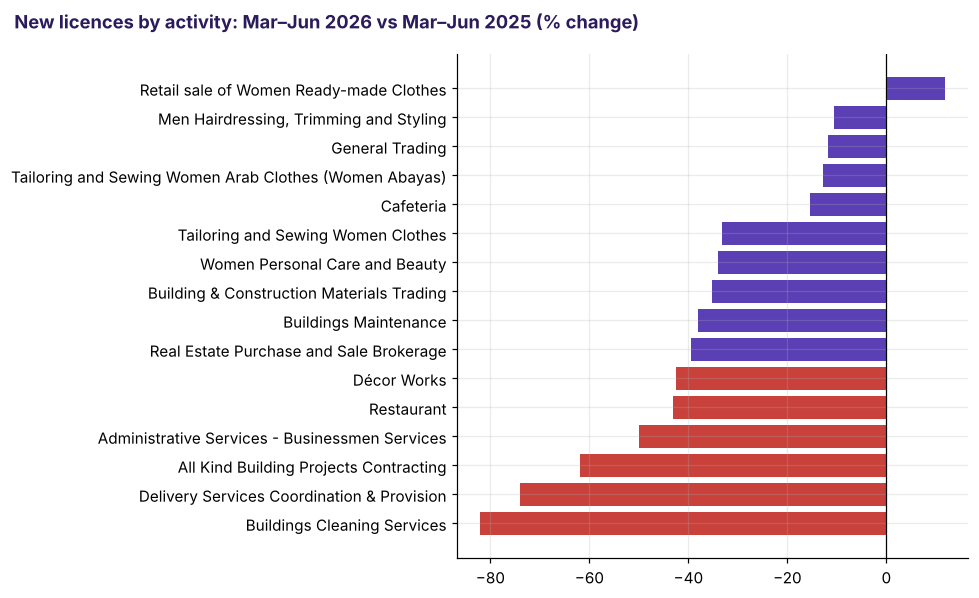

In [5]:
# Which activities and areas fell most? (Mar–Jun 2026 vs Mar–Jun 2025)
act  = pd.read_csv("data/by_activity.csv", index_col=0)
area = pd.read_csv("data/by_area.csv", index_col=0)
typ  = df[["professional", "commercial", "industrial"]]; typ.index = typ.index.astype(str)
win = (("2025-03", "2025-06"), ("2026-03", "2026-06"))
act_chg  = fk.change_table(act.drop(columns="Other"), *win, min_before=25)
area_chg = fk.change_table(area.drop(columns=["Other", "Unknown"]), *win, min_before=40)
type_chg = fk.change_table(typ, *win, min_before=20)
display(type_chg); display(act_chg); display(area_chg)

fig, ax = plt.subplots(figsize=(9, 5.5))
s = act_chg["change_%"].sort_values()
ax.barh(s.index, s.values, color=[RED if v < -40 else PURPLE for v in s.values])
ax.axvline(0, color="black", lw=0.8)
fig.suptitle("New licences by activity: Mar–Jun 2026 vs Mar–Jun 2025 (% change)", x=0.02, ha="left", fontweight="bold", color=NAVY)
plt.tight_layout(); plt.savefig(OUT / "fig2_activity_change.png", dpi=200); plt.show()

## 2. Back-test in normal times
Train up to Oct 2024, forecast Jan 2025 – Feb 2026 (14 months, all before the March 2026 shock). Models: **seasonal naive** (same month last year), **SARIMAX** (log scale, with Ramadan/Eid/COVID/data-source regressors), **Prophet**, **XGBoost** (seasonal-lag features) and their **average (ensemble)**.

In [6]:
metrics_normal, pred_normal = fk.backtest(df, TARGET, TRAIN_START, NORMAL_TEST[0], NORMAL_TEST[1], use_prophet=USE_PROPHET)
metrics_normal.round(1)

22:35:50 - cmdstanpy - INFO - Chain [1] start processing


22:35:50 - cmdstanpy - INFO - Chain [1] done processing


,MAE,MAPE_%,Bias_%,n
Seasonal naive,125.9,19.3,-19.9,14.0
SARIMAX,75.8,11.8,-8.7,14.0
Prophet,112.8,18.5,10.6,14.0
XGBoost,127.1,19.7,-20.0,14.0
Ensemble (avg),74.5,11.7,-6.0,14.0


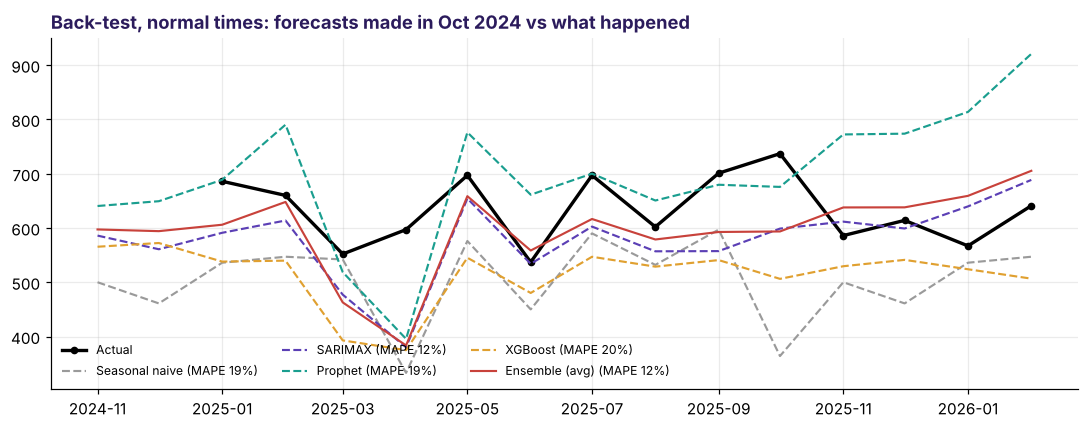

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
x = pred_normal.index.to_timestamp()
ax.plot(x, pred_normal["actual"], color="black", lw=2.2, label="Actual", marker="o", ms=4)
colors = {"Seasonal naive": GREY, "SARIMAX": PURPLE, "Prophet": TEAL, "XGBoost": "#E0A030", "Ensemble (avg)": RED}
for c in pred_normal.columns[1:]:
    ax.plot(x, pred_normal[c], lw=1.4, ls="--" if c != "Ensemble (avg)" else "-", color=colors.get(c), label=f"{c} (MAPE {metrics_normal.loc[c,'MAPE_%']:.0f}%)")
ax.set_title("Back-test, normal times: forecasts made in Oct 2024 vs what happened", loc="left", fontweight="bold", color=NAVY)
ax.legend(ncol=3, fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "fig3_backtest_normal.png", dpi=200); plt.show()

## 3. The shock test — what if we'd forecast in Feb 2026?
Train up to Feb 2026 (no knowledge of the coming shock) and forecast Mar–Jun 2026. Every trend model badly over-predicts — this is the slide that shows *why* scenarios matter.

In [8]:
metrics_shock, pred_shock = fk.backtest(df, TARGET, TRAIN_START, SHOCK_TEST[0], SHOCK_TEST[1], use_prophet=USE_PROPHET)
display(metrics_shock.round(1)); pred_shock.round(0)

,MAE,MAPE_%,Bias_%,n
Seasonal naive,223.5,64.7,60.0,4.0
SARIMAX,245.4,67.9,65.9,4.0
Prophet,311.6,85.7,83.7,4.0
XGBoost,246.4,68.3,66.2,4.0
Ensemble (avg),267.8,74.0,71.9,4.0


,actual,Seasonal naive,SARIMAX,Prophet,XGBoost,Ensemble (avg)
2026-03,416.0,552.0,518.0,617.0,554.0,563.0
2026-04,382.0,597.0,600.0,683.0,647.0,643.0
2026-05,300.0,697.0,569.0,625.0,580.0,591.0
2026-06,391.0,537.0,783.0,810.0,694.0,763.0


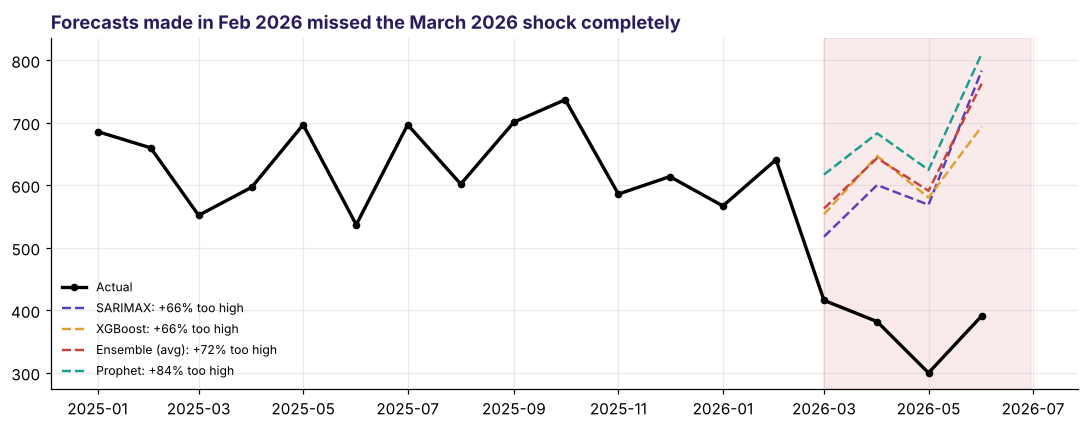

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
hist = df.loc["2025-01":"2026-06", TARGET]
ax.plot(hist.index.to_timestamp(), hist.values, color="black", lw=2.2, marker="o", ms=4, label="Actual")
x = pred_shock.index.to_timestamp()
for c in ["SARIMAX", "XGBoost", "Ensemble (avg)"] + (["Prophet"] if "Prophet" in pred_shock else []):
    ax.plot(x, pred_shock[c], lw=1.6, ls="--", color=colors.get(c), label=f"{c}: {metrics_shock.loc[c,'Bias_%']:+.0f}% too high")
ax.axvspan(pd.Timestamp("2026-03-01"), pd.Timestamp("2026-06-30"), color=RED, alpha=0.1)
ax.set_title("Forecasts made in Feb 2026 missed the March 2026 shock completely", loc="left", fontweight="bold", color=NAVY)
ax.legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "fig4_shock_test.png", dpi=200); plt.show()

## 4. How big was the shock?
Fit SARIMAX on all data with a `disruption` dummy (Mar 2026 onward), controlling for seasonality, Ramadan, Eid, COVID and the change in data source. Ramadan matters here: in 2026 it fell in Feb–Mar, overlapping the start of the disruption.

In [10]:
ce = fk.shock_effect(df, TARGET, TRAIN_START)
p = ce["result"].params
print(f"Shock effect on new licences: {ce['effect_%']:.0f}%  (90% range {ce['effect_lo_%']:.0f}% to {ce['effect_hi_%']:.0f}%) — only 4 months of data, so treat as indicative")
effects = pd.Series({k: (np.exp(p[k]) - 1) * 100 for k in ["ramadan_share", "eid_fitr", "eid_adha", "covid", "disruption"]}, name="effect_%")
effects.round(1)

Shock effect on new licences: -34%  (90% range -48% to -18%) — only 4 months of data, so treat as indicative


ramadan_share     3.8
eid_fitr        -20.8
eid_adha        -23.7
covid           -68.4
disruption      -34.4
Name: effect_%, dtype: float64

## 5. Scenario forecasts to Dec 2027
The model's `disruption` input becomes a **scenario dial** (1 = the full Mar–Jun 2026 effect, 0 = normal):
- **A. Disruption persists through 2027** — dial stays at 1
- **B. Normalises in H1 2027** — dial fades Jan → Jun 2027 (in line with the Central Bank's 2027 rebound view)
- **C. Quick recovery by Jan 2027** — dial fades Sep 2026 → Jan 2027

In [11]:
scen, scen_res = fk.forecast_scenarios(df, TARGET, TRAIN_START, HORIZON_END)
scen_table = pd.DataFrame({k: v["mean"] for k, v in scen.items()}).round(0)
summary = pd.DataFrame({k: {"H2 2026": v.loc["2026-07":"2026-12", "mean"].sum(), "2027": v.loc["2027-01":"2027-12", "mean"].sum()} for k, v in scen.items()}).T.round(0)
summary["2027 vs 2025 actual_%"] = (summary["2027"] / df.loc["2025-01":"2025-12", TARGET].sum() - 1) * 100
display(summary.round(1)); scen_table

,H2 2026,2027,2027 vs 2025 actual_%
A. Disruption persists through 2027,2509.0,5622.0,-26.7
B. Normalises in H1 2027,2509.0,7813.0,1.9
C. Quick recovery by Jan 2027,2825.0,8565.0,11.7


,A. Disruption persists through 2027,B. Normalises in H1 2027,C. Quick recovery by Jan 2027
month,,,
2026-07,393.0,393.0,393.0
2026-08,383.0,383.0,383.0
2026-09,404.0,404.0,404.0
2026-10,444.0,444.0,492.0
2026-11,442.0,442.0,545.0
2026-12,443.0,443.0,607.0
2027-01,468.0,468.0,713.0
2027-02,504.0,550.0,768.0
2027-03,398.0,470.0,607.0


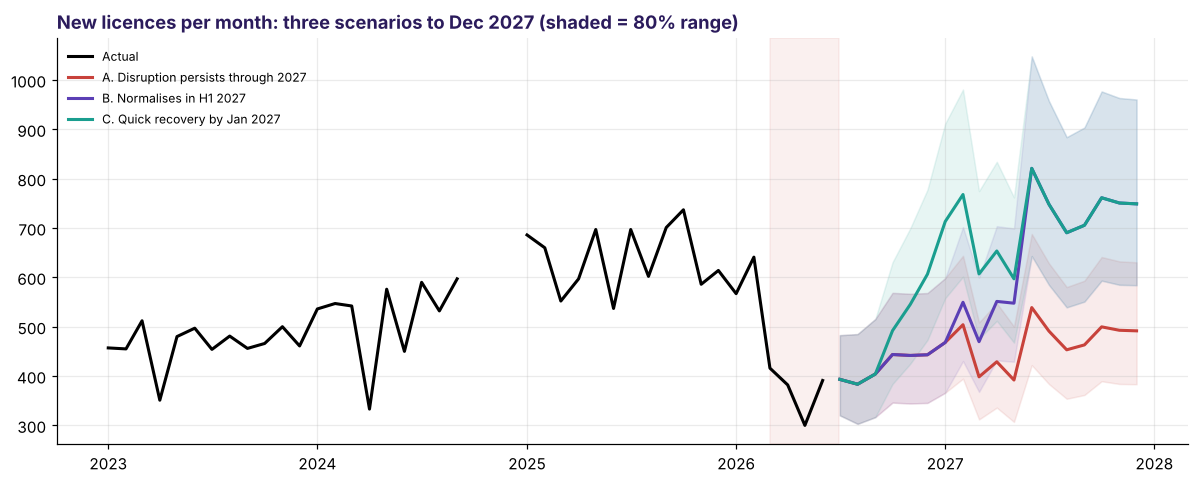

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
h = df.loc["2023-01":, TARGET]
ax.plot(h.index.to_timestamp(), h.values, color="black", lw=2, label="Actual")
sc_colors = [RED, PURPLE, TEAL]
for (name, f), c in zip(scen.items(), sc_colors):
    x = f.index.to_timestamp()
    ax.plot(x, f["mean"], color=c, lw=2, label=name)
    ax.fill_between(x, f["lo"], f["hi"], color=c, alpha=0.10)
ax.axvspan(pd.Timestamp("2026-03-01"), pd.Timestamp("2026-06-30"), color=RED, alpha=0.08)
ax.set_title("New licences per month: three scenarios to Dec 2027 (shaded = 80% range)", loc="left", fontweight="bold", color=NAVY)
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(OUT / "fig5_scenarios.png", dpi=200); plt.show()

## 6. The stock-flow equation (active licences)
$$\text{Active}_t = \text{Active}_{t-1} + \text{New}_t - \text{Cancelled}_t - \text{Lapsed}_t, \qquad \text{Lapsed}_t = \text{Due}_t\,(1 - r_t)$$
We don't have monthly renewal data, so we **back out the renewal rate $r$ from DED's own published figures** (active licences +16% y/y, renewals and cancellations in Q1 2026). Then we project active licences under each scenario, letting $r$ dip by up to 2 points while the disruption lasts (an assumption — replace with the organisers' data).

In [13]:
new_12m = df.loc["2025-04":"2026-03", "total"].sum()
cal = fk.calibrate_renewal_rate(ACTIVE_NOW, ACTIVE_GROWTH_YOY, new_12m, CANCELLED_PER_MONTH, RENEWALS_PER_MONTH)
print(f"Implied: {cal['lapsed_per_month']:.0f} licences lapse per month → renewal rate r = {cal['renewal_rate']:.1%}")

# Start from end of Q1 2026, use actual new licences Apr–Jun 2026, then each scenario's forecast
paths = fk.scenario_paths(pd.period_range("2026-04", HORIZON_END, freq="M"))
stock = {}
for name, f in scen.items():
    new = pd.concat([df.loc["2026-04":"2026-06", "total"], f["mean"]])
    dial = paths[name].reindex(new.index).fillna(1.0)
    r = cal["renewal_rate"] - 0.02 * dial          # assumption: up to −2 pts renewal while the disruption lasts
    stock[name] = fk.stock_flow(ACTIVE_NOW, new, RENEWALS_PER_MONTH, r, CANCELLED_PER_MONTH)
active = pd.DataFrame({k: v["active"] for k, v in stock.items()}).round(0)
active.loc[["2026-06", "2026-12", "2027-06", "2027-12"]]

Implied: 71 licences lapse per month → renewal rate r = 97.6%


,A. Disruption persists through 2027,B. Normalises in H1 2027,C. Quick recovery by Jan 2027
month,,,
2026-06,42075.0,42075.0,42075.0
2026-12,43381.0,43381.0,43787.0
2027-06,44908.0,45768.0,47111.0
2027-12,46596.0,49337.0,50681.0


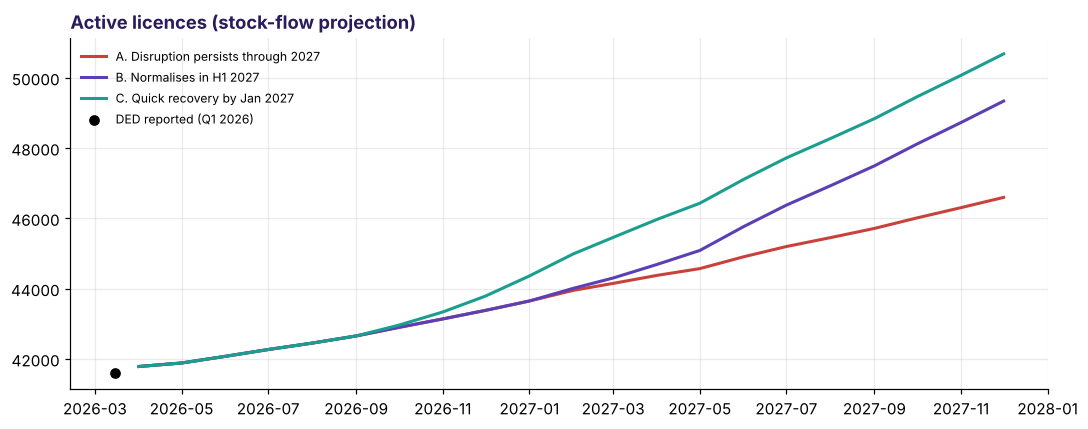

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
for (name, s), c in zip(stock.items(), sc_colors):
    ax.plot(s.index.to_timestamp(), s["active"], color=c, lw=2, label=name)
ax.scatter([pd.Timestamp("2026-03-15")], [ACTIVE_NOW], color="black", zorder=5, label="DED reported (Q1 2026)")
ax.set_title("Active licences (stock-flow projection)", loc="left", fontweight="bold", color=NAVY)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(OUT / "fig6_active_stock.png", dpi=200); plt.show()

## 7. Export — the "integration" piece
Outputs a CSV and a **JSON feed** (the format a DED dashboard or the Ajman One app could consume), plus a self-contained interactive dashboard (`outputs/dashboard.html`, works offline).

In [15]:
rows = []
for name, f in scen.items():
    for p_, r_ in f.iterrows():
        rows.append({"month": str(p_), "scenario": name, "indicator": TARGET, "forecast": round(r_["mean"]),
                     "lower_80": round(r_["lo"]), "upper_80": round(r_["hi"]),
                     "active_licences": int(stock[name].loc[p_, "active"])})
fc = pd.DataFrame(rows); fc.to_csv(OUT / "forecast_scenarios.csv", index=False)
metrics_normal.round(2).to_csv(OUT / "backtest_normal.csv"); metrics_shock.round(2).to_csv(OUT / "backtest_shock.csv")
feed = {"indicator": "new_economic_licences", "unit": "licences per month", "source": "Ajman DED open data",
        "last_actual_month": str(df[TARGET].last_valid_index()),
        "shock_effect_pct": round(float(ce["effect_%"]), 1),
        "backtest_mape_pct": {k: round(float(v), 1) for k, v in metrics_normal["MAPE_%"].items()},
        "scenarios": {name: [{"month": str(p_), "value": round(r_["mean"]), "lo": round(r_["lo"]), "hi": round(r_["hi"])}
                              for p_, r_ in f.iterrows()] for name, f in scen.items()}}
(OUT / "forecast_feed.json").write_text(json.dumps(feed, indent=2))
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  backtest_normal.csv
  backtest_shock.csv
  dashboard.html
  fig1_history.png
  fig2_activity_change.png
  fig3_backtest_normal.png
  fig4_shock_test.png
  fig5_scenarios.png
  fig6_active_stock.png
  forecast_feed.json
  forecast_scenarios.csv
  slide_scenarios.png
  slide_shock.png


In [16]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
figd = make_subplots(rows=2, cols=2, subplot_titles=("New licences: actual + scenarios", "Active licences (stock-flow)",
                                                     "Activities hit hardest (Mar–Jun 2026 vs 2025, %)", "Back-test error (MAPE %, normal times)"),
                     vertical_spacing=0.14, horizontal_spacing=0.08)
h = df.loc["2023-01":, TARGET]
figd.add_trace(go.Scatter(x=h.index.to_timestamp(), y=h.values, name="Actual", line=dict(color="black", width=2)), 1, 1)
for (name, f), c in zip(scen.items(), sc_colors):
    figd.add_trace(go.Scatter(x=f.index.to_timestamp(), y=f["mean"].round(), name=name, line=dict(color=c, width=2)), 1, 1)
    figd.add_trace(go.Scatter(x=stock[name].index.to_timestamp(), y=stock[name]["active"].round(), name=name, showlegend=False, line=dict(color=c, width=2)), 1, 2)
s = act_chg["change_%"].sort_values()
figd.add_trace(go.Bar(x=s.values, y=s.index, orientation="h", marker_color=[RED if v < -40 else PURPLE for v in s.values], showlegend=False), 2, 1)
m = metrics_normal["MAPE_%"].sort_values()
figd.add_trace(go.Bar(x=m.index, y=m.values.round(1), marker_color=PURPLE, showlegend=False), 2, 2)
figd.update_layout(height=820, title="Ajman new-licence forecast dashboard (practice run on DED open data)", template="plotly_white",
                   legend=dict(orientation="h", y=1.08), margin=dict(l=40, r=20, t=110, b=40))
figd.write_html(OUT / "dashboard.html", include_plotlyjs=True)
print("Dashboard saved to outputs/dashboard.html")

Dashboard saved to outputs/dashboard.html


## On the day — swapping in the organisers' data
1. Put their file in `data/`, make sure it has a monthly `month` column (YYYY-MM) and the target column.
2. If it isn't licences, still keep the calendar columns: re-run `prepare_data.py`'s `ramadan_eid_features()` on the new months.
3. Set `TARGET`, `TRAIN_START`, test windows in CONFIG → *Run All* (~1 minute).
4. Check `metrics_normal` — pick the best model or keep the ensemble. Use `fig4` + `fig5` on the slides.
5. If they give renewals / cancellations / active counts, replace the four stock-flow inputs in CONFIG.